# 1. Generate the data

## Goal
Build the **channel time series** used by all three estimation notebooks.
We will inspect a full XYZ spectral matrix, draw stationary XYZ data, make
channel A nonstationary, evolve the orbit response over seven days, and add gaps.

Nothing is fitted here. Later notebooks estimate channel PSDs, cross spectra
and coherence. Run the cells in order; rerunning regenerates the same seeded
files in `outputs/notebooks/data/`.

## Setup
From the repository root, run `uv sync --locked --extra gapped --group notebooks`.
Launch Jupyter with the same environment, or use the execution command in
[Install and run](../running.md). No archived data or orbit download is needed.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch

from lisa_case_studies.noise import XYZ_TO_AET, coherence
from lisa_case_studies.notebook_tools import COLORS, style
from lisa_case_studies.orbit_reference import DAY, LINKS, orbit_light_times
from lisa_case_studies.tutorial_data import (
    MatrixSimulation,
    amplitude,
    data_receipt,
    workspace,
)

style()
DATA = workspace() / "data"
DATA.mkdir(parents=True, exist_ok=True)
DT, DURATION, SEED = 5.0, 7 * DAY, 7
N = int(DURATION / DT)

## Step 1 — Specify a full XYZ spectral matrix
The reference is the orbit-dependent $3\times3$ XYZ matrix $S_0(t,f)$.
A prescribed smooth positive-definite matrix $R(f)$ changes its auto and cross
spectra: $S(t,f)=L_0(t,f)R(f)L_0(t,f)^\dagger$.

The simulator interpolates eight reference factors acting on shared Gaussian
Fourier noise. This is a controlled spectral-matrix simulation, not an
end-to-end instrument or time-delay simulation. A relative $10^{-12}$
eigenvalue floor regularizes numerical null modes and is shared by the
injection and reference. The [simulation notes](../notebook_models.md) give details.

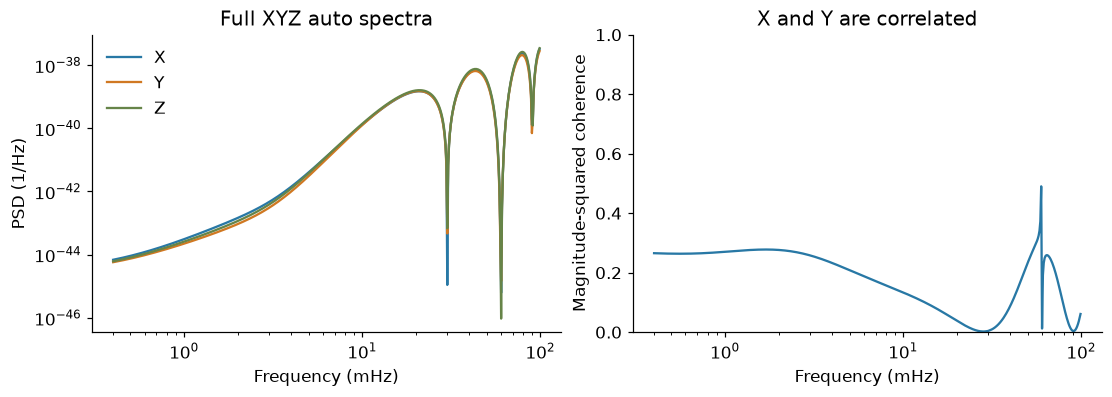

In [2]:
epochs = (np.arange(8) + 0.5) * DURATION / 8
light_times, orbit_origin = orbit_light_times(epochs, model="keplerian")
midpoint_delays, _ = orbit_light_times(np.array([DURATION / 2]))
frequency = np.geomspace(0.4e-3, 99e-3, 500)
stationary = MatrixSimulation(65536, DT, np.array([0.0]), midpoint_delays)
stationary_truth = stationary.spectrum(np.array([0.0]), frequency)[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for j, channel in enumerate("XYZ"):
    axes[0].loglog(
        frequency * 1000,
        stationary_truth[:, j, j].real,
        color=COLORS[channel],
        label=channel,
    )
axes[0].set(
    xlabel="Frequency (mHz)", ylabel="PSD (1/Hz)", title="Full XYZ auto spectra"
)
axes[0].legend(frameon=False)
axes[1].semilogx(
    frequency * 1000, coherence(stationary_truth)[:, 0, 1], color=COLORS["X"]
)
axes[1].set(
    xlabel="Frequency (mHz)",
    ylabel="Magnitude-squared coherence",
    ylim=(0, 1),
    title="X and Y are correlated",
)
plt.show()

The dips come from the known response. The nonzero coherence means XYZ cannot
be fitted as three independent channels. The stationary lesson starts below
25 mHz to introduce the vanilla spline fit before tackling the response nulls.

## Step 2 — Draw real stationary XYZ data
Freeze the orbit geometry, retain the same full spectral matrix, and draw a
real Gaussian time series. The raw record contains the full simulated band;
the estimation notebook selects its analysis band explicitly.

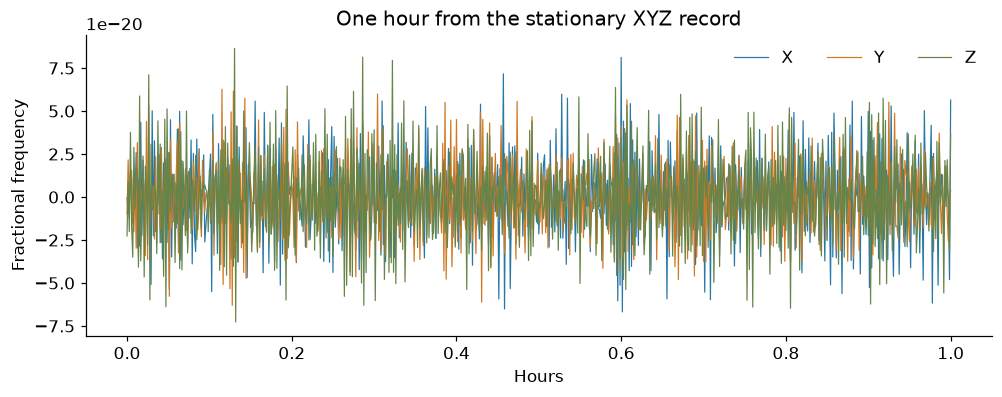

In [3]:
stationary_xyz = stationary.draw(SEED + 1)
np.savez_compressed(
    DATA / "stationary_xyz.npz",
    xyz=stationary_xyz,
    time=stationary.time,
    dt=DT,
    light_times=midpoint_delays[0],
    plot_frequency=frequency,
    plot_truth=stationary_truth,
)
fig, ax = plt.subplots(layout="constrained")
first_hour = stationary.time <= 3600
for j, channel in enumerate("XYZ"):
    ax.plot(
        stationary.time[first_hour] / 3600,
        stationary_xyz[first_hour, j],
        color=COLORS[channel],
        lw=0.8,
        label=channel,
    )
ax.set(
    xlabel="Hours",
    ylabel="Fractional frequency",
    title="One hour from the stationary XYZ record",
)
ax.legend(ncol=3, frameon=False)
plt.show()

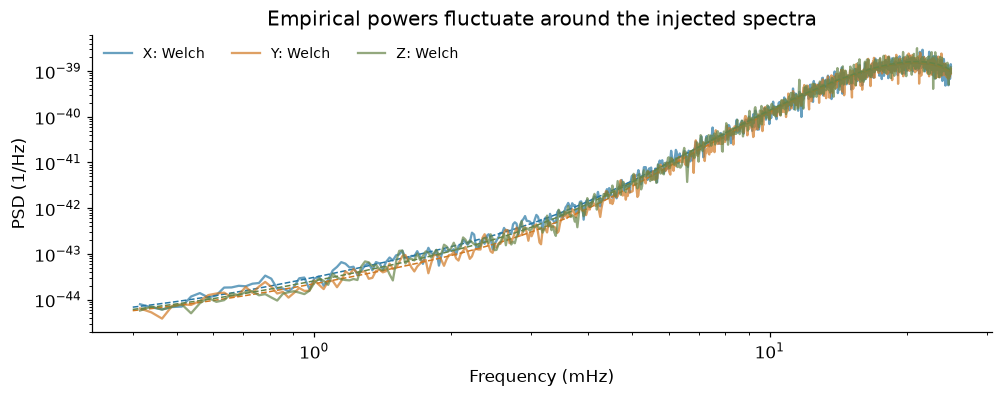

In [4]:
fig, ax = plt.subplots(layout="constrained")
for j, channel in enumerate("XYZ"):
    f_welch, p_welch = welch(
        stationary_xyz[:, j], fs=1 / DT, nperseg=8192, window="hann"
    )
    keep = (f_welch >= 0.4e-3) & (f_welch <= 25e-3)
    ax.loglog(
        f_welch[keep] * 1000,
        p_welch[keep],
        color=COLORS[channel],
        alpha=0.7,
        label=f"{channel}: Welch",
    )
    band = frequency <= 25e-3
    ax.loglog(
        frequency[band] * 1000,
        stationary_truth[band, j, j].real,
        color=COLORS[channel],
        ls="--",
        lw=1,
    )
ax.set(
    xlabel="Frequency (mHz)",
    ylabel="PSD (1/Hz)",
    title="Empirical powers fluctuate around the injected spectra",
)
ax.legend(ncol=3, fontsize=9, frameon=False)
plt.show()

## Step 3 — Make channel A nonstationary
Form $A=(Z-X)/\sqrt2$ from a frozen-geometry XYZ draw and multiply it by a
slow amplitude envelope $a(t)$. Its local PSD is $a(t)^2 S_{A,0}(f)$.
This is a controlled amplitude change, not an orbital prediction.

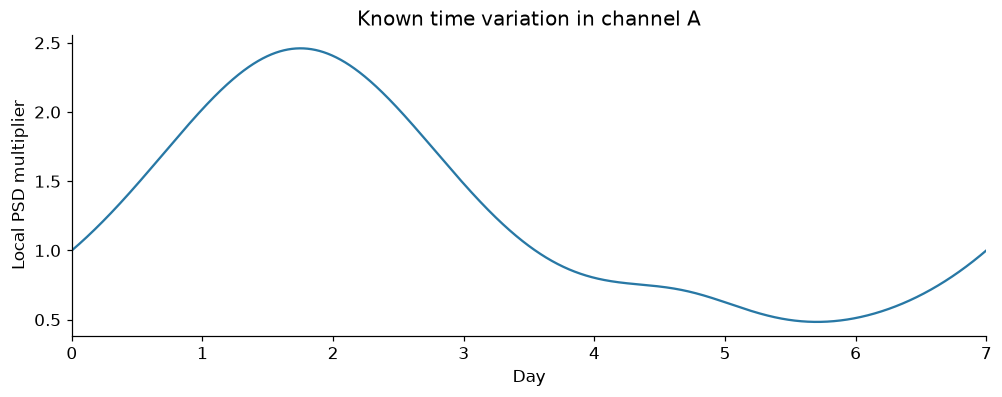

In [5]:
frozen_week = MatrixSimulation(N, DT, np.array([0.0]), midpoint_delays)
a_vector = XYZ_TO_AET[0]
base_a = frozen_week.draw(SEED + 2) @ a_vector
channel_a = amplitude(frozen_week.time, DURATION) * base_a
np.savez_compressed(
    DATA / "scalar_a.npz",
    data=channel_a,
    time=frozen_week.time,
    dt=DT,
    duration=DURATION,
    light_times=midpoint_delays[0],
)
fig, ax = plt.subplots(layout="constrained")
ax.plot(
    frozen_week.time / DAY,
    amplitude(frozen_week.time, DURATION) ** 2,
    color=COLORS["X"],
)
ax.set(
    xlabel="Day",
    ylabel="Local PSD multiplier",
    xlim=(0, 7),
    title="Known time variation in channel A",
)
plt.show()

## Step 4 — Evolve the orbit reference over seven days
Keep the residual matrix fixed in time and change the reference factors with
the orbit. This isolates orbital nonstationarity from a freely changing noise
spectrum. The exact same latent noise drives all epochs.

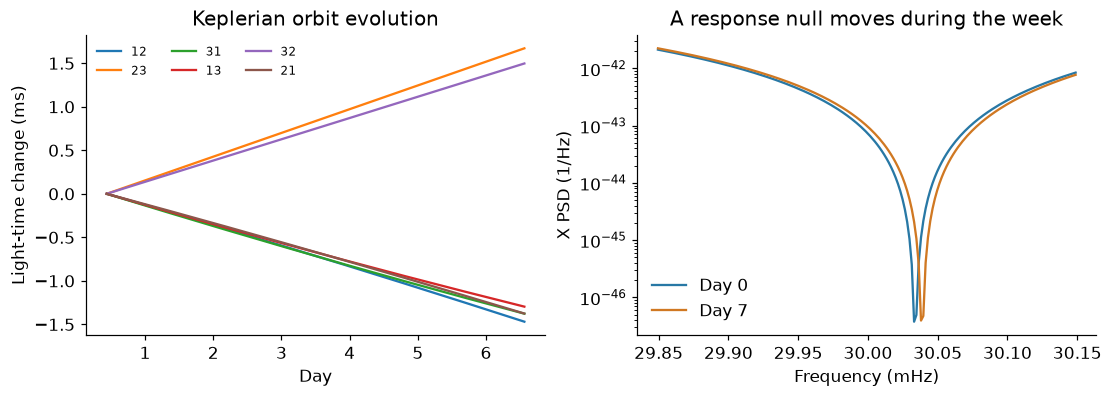

In [6]:
short = MatrixSimulation(N, DT, epochs, light_times)
short_xyz = short.draw(SEED + 3)
np.savez_compressed(
    DATA / "short_xyz.npz",
    xyz=short_xyz,
    time=short.time,
    n=N,
    dt=DT,
    epochs=epochs,
    light_times=light_times,
    orbit_origin=orbit_origin,
)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for j, link in enumerate(LINKS):
    axes[0].plot(
        epochs / DAY, 1000 * (light_times[:, j] - light_times[0, j]), label=str(link)
    )
axes[0].set(
    xlabel="Day", ylabel="Light-time change (ms)", title="Keplerian orbit evolution"
)
axes[0].legend(ncol=3, fontsize=8, frameon=False)
near = np.arange(round(0.02985 * DURATION), round(0.03015 * DURATION))
null_frequency = short.frequency[near]
null_truth = short.spectrum(np.array([0.0, DURATION - DT]), null_frequency)
for j, label in enumerate(("Day 0", "Day 7")):
    axes[1].semilogy(
        null_frequency * 1000,
        null_truth[j, :, 0, 0].real,
        color=(COLORS["X"], COLORS["Y"])[j],
        label=label,
    )
axes[1].set(
    xlabel="Frequency (mHz)",
    ylabel="X PSD (1/Hz)",
    title="A response null moves during the week",
)
axes[1].legend(frameon=False)
plt.show()

## Step 5 — Describe gaps without inventing observations
GapLike makes the time mask and tapered observation windows. The missing
samples remain missing; a window is an observation operator, not extra data.
We save both the mask and windows for the fourth notebook.

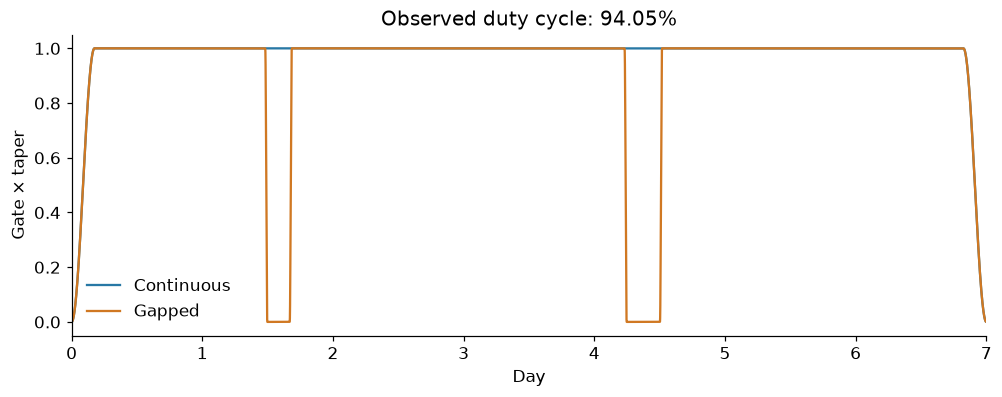

In [7]:
import gaplike as gl

intervals = [(1.5 * DAY, 1.5 * DAY + 4 * 3600), (4.25 * DAY, 4.25 * DAY + 6 * 3600)]
mask = gl.gaps.mask_from_intervals(N, DT, intervals)
continuous_window = gl.gaps.segment_window(N, 0.05)
gapped_window = gl.gaps.effective_window(
    gl.gaps.gate_from_mask(mask, DT, taper_s=1800), continuous_window
)
np.savez_compressed(
    DATA / "windows.npz",
    mask=mask,
    continuous=continuous_window,
    gapped=gapped_window,
    intervals=np.asarray(intervals),
)
fig, ax = plt.subplots(layout="constrained")
ax.plot(
    short.time / DAY, continuous_window, color=COLORS["continuous"], label="Continuous"
)
ax.plot(short.time / DAY, gapped_window, color=COLORS["gapped"], label="Gapped")
ax.set(
    xlabel="Day",
    ylabel="Gate × taper",
    xlim=(0, 7),
    title=f"Observed duty cycle: {mask.mean():.2%}",
)
ax.legend(frameon=False)
plt.show()

## Checks
Verify shapes and finite values before fitting. The saved truth is reserved
for plots and final errors; it does not select inference priors or knots.

In [8]:
assert stationary_xyz.shape == (65536, 3) and short_xyz.shape == (N, 3)
assert np.isfinite(stationary_xyz).all() and np.isfinite(short_xyz).all()
assert np.all(gapped_window[~mask] == 0)
data_receipt(
    DATA,
    seed=SEED,
    n_samples=N,
    dt_seconds=DT,
    duration_days=7,
    orbit="keplerian",
    model="evolving full spectral-matrix factors",
    reference_eigenvalue_floor=1e-12,
)
pd.DataFrame(
    [
        {
            "Dataset": "Stationary XYZ",
            "Samples": len(stationary_xyz),
            "Used by": "Notebook 3",
        },
        {
            "Dataset": "Nonstationary A",
            "Samples": len(channel_a),
            "Used by": "Notebook 2",
        },
        {
            "Dataset": "Seven-day XYZ + mask",
            "Samples": len(short_xyz),
            "Used by": "Notebook 4",
        },
    ]
)

,Dataset,Samples,Used by
0,Stationary XYZ,65536,Notebook 3
1,Nonstationary A,120960,Notebook 2
2,Seven-day XYZ + mask,120960,Notebook 4


## Next steps
[Fit the time-varying A PSD](02_time_varying_psd.ipynb), or continue to
[standard multivariate XYZ estimation](03_xyz_psd.ipynb).